<a href="https://colab.research.google.com/github/AnjanPayra/DAVES-Dataset-Anchored-Virtual-Eye-Screening-Colab-/blob/main/DAVES_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DAVES: Dataset-Anchored Virtual Eye Screening (Colab)

Headset-free replay of real Humphrey visual fields from the open **UWHVF** dataset. A gaze-gated Bayesian test (DAVES) is compared with a fixed staircase. No headset and no participants needed.

**Run order:** 1 Setup, 2 Quick check (seconds, uses the shipped results), 3 Full replay (minutes, real UWHVF download), 4 Optional experiments, 5 Synthetic gaze/physiology check, 6 Download.

Limits: the abnormal label is a proxy (mean total deviation of -3 dB or worse), not a diagnosis. The oculomotor and physiology modules are checked on synthetic data only. Not a medical device.

## 1. Setup

In [1]:
#@title Get the project { run: "auto" }
#@markdown Leave the repo URL empty to upload `daves_project.zip` instead.
REPO_URL = ""  #@param {type:"string"}

import os, subprocess, sys, zipfile

if not os.path.isdir("daves_project"):
    if REPO_URL.strip():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL.strip(), "daves_project"], check=True)
    else:
        try:
            from google.colab import files
            print("Upload daves_project.zip")
            name = next(iter(files.upload()))
        except ImportError:
            name = "daves_project.zip"   # outside Colab: the zip must be in the current folder
        with zipfile.ZipFile(name) as z:
            z.extractall(".")
os.chdir("daves_project")
print("Working in", os.getcwd())
print(sorted(os.listdir(".")))

Upload daves_project.zip


Saving daves_project.zip to daves_project.zip
Working in /content/daves_project
['Makefile', 'README.md', 'daves', 'pyproject.toml', 'reference_results', 'requirements.txt', 'results', 'tests']


In [2]:
!pip -q install -r requirements.txt
import sys; sys.path.insert(0, ".")
import numpy, pandas, scipy, matplotlib
print("numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0


In [ ]:
!python -m pytest -q

## 2. Quick check: rebuild Tables 9 to 11 and Figures 7 to 11 from the shipped run (about 20 seconds)
Uses `reference_results/replay_eyes.csv`, the 200-eye run reported in the paper.

In [3]:
import os, shutil
os.makedirs("results", exist_ok=True)
shutil.copy("reference_results/replay_eyes.csv", "results/replay_eyes.csv")
!python -m daves.technical_stats --outdir results
!python -m daves.plots --outdir results

         metric  staircase  staircase_lo  staircase_hi   daves  daves_lo  daves_hi    diff  diff_lo  diff_hi  wilcoxon_p  cohen_dz
     point_rmse      3.879         3.786         3.967   1.312     1.276     1.354   2.566    2.452    2.671       0.000     3.219
       n_trials    714.075       708.904       719.011 376.265   369.949   383.192 337.810  327.140  347.490       0.000     4.743
     duration_s   1284.988      1275.452      1293.940 677.449   666.022   690.020 607.539  588.490  625.036       0.000     4.691
            auc      0.797         0.734         0.857   0.837     0.777     0.890   0.040   -0.009    0.089       0.106       NaN
sens_at_90_spec      0.580           NaN           NaN   0.670       NaN       NaN     NaN      NaN      NaN         NaN       NaN 

         method   bias  bias_lo  bias_hi  loa_low  loa_high  loa_width  pearson_r  slope_diff_on_truth  slope_p
Fixed staircase -2.852   -2.986   -2.710   -4.782    -0.921      3.861      0.991               -0.2

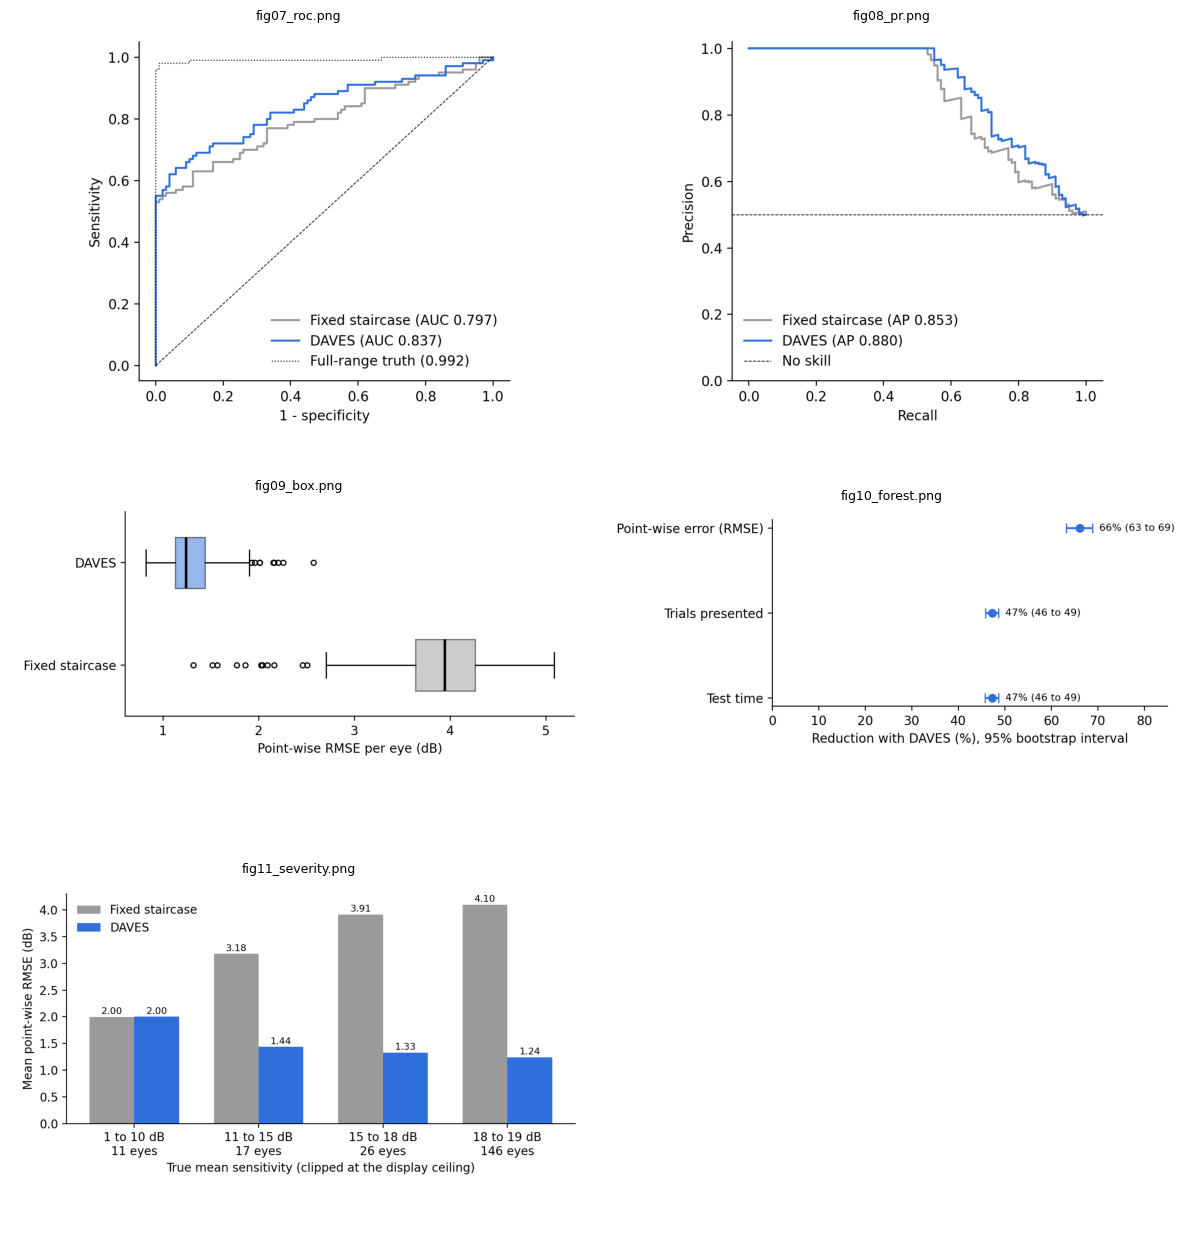

In [4]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
import pandas as pd
pd.set_option("display.width", 200)

def show(names, outdir="results", cols=2):
    rows = (len(names) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, n in zip(axes.ravel(), names):
        ax.imshow(mpimg.imread(f"{outdir}/{n}")); ax.set_title(n, fontsize=9)
    plt.tight_layout(); plt.show()

FIGS = ["fig07_roc.png", "fig08_pr.png", "fig09_box.png", "fig10_forest.png", "fig11_severity.png"]
show(FIGS)

In [ ]:
for f in ("technical_stats", "agreement", "severity_strata"):
    print(f"\n{f}.csv"); display(pd.read_csv(f"results/{f}.csv").round(3))

## 3. Full replay on real UWHVF fields
Downloads UWHVF (about 53 MB, BSD licence) and tests virtual observers built from real first-visit fields with both methods.

`PER_CLASS` = eyes per class (abnormal and normal). The paper used **100** (200 eyes, a long run on a Colab CPU). Start with **10** to check that it works. Results differ a little from the paper because a smaller random sample is used.

In [5]:
#@title Replay settings { run: "auto" }
PER_CLASS = 10  #@param {type:"slider", min:5, max:100, step:5}
SEED = 1        #@param {type:"integer"}
CEILING_DB = 19 #@param {type:"number"}
OUT = "results_full"

In [6]:
import time
t0 = time.time()
!python -m daves.replay_uwhvf --data data/alldata.json --per-class {PER_CLASS} --seed {SEED} --ceiling-db {CEILING_DB} --outdir {OUT}
print(f"done in {(time.time()-t0)/60:.1f} min")

7379 eyes with a valid first field. MTD median -3.86 dB, 61% at or below -3.0 dB

Replay summary (virtual observers built from real Humphrey fields)
          method  eyes  bias_db  loa_halfwidth_db  point_rmse_db  mean_trials  mean_duration_s  auc_abnormal  sens_at_90_spec
Fixed staircase    20   -2.732             2.289          3.817       715.50         1286.752          0.75              0.5
         GA-BAT    20   -0.629             1.380          1.305       380.25          684.246          0.84              0.6

Upper bounds for the same eyes: AUC with the clipped true mean sensitivity = 0.950, with the full-range Humphrey mean sensitivity = 1.000

Saved to results_full/
done in 0.1 min


         metric  staircase  staircase_lo  staircase_hi   daves  daves_lo  daves_hi    diff  diff_lo  diff_hi  wilcoxon_p  cohen_dz
     point_rmse      3.817         3.536         4.070   1.305     1.143     1.513   2.512    2.063    2.891       0.000     2.467
       n_trials    715.500       699.844       729.301 380.250   358.700   404.554 335.250  300.992  364.201       0.000     4.278
     duration_s   1286.752      1258.445      1312.187 684.246   646.248   728.100 602.506  541.419  653.950       0.000     4.334
            auc      0.750         0.516         0.934   0.840     0.608     0.979   0.090   -0.166    0.327       0.448       NaN
sens_at_90_spec      0.500           NaN           NaN   0.600       NaN       NaN     NaN      NaN      NaN         NaN       NaN 

         method   bias  bias_lo  bias_hi  loa_low  loa_high  loa_width  pearson_r  slope_diff_on_truth  slope_p
Fixed staircase -2.732   -3.165   -2.210   -5.021    -0.443      4.577      0.993               -0.2

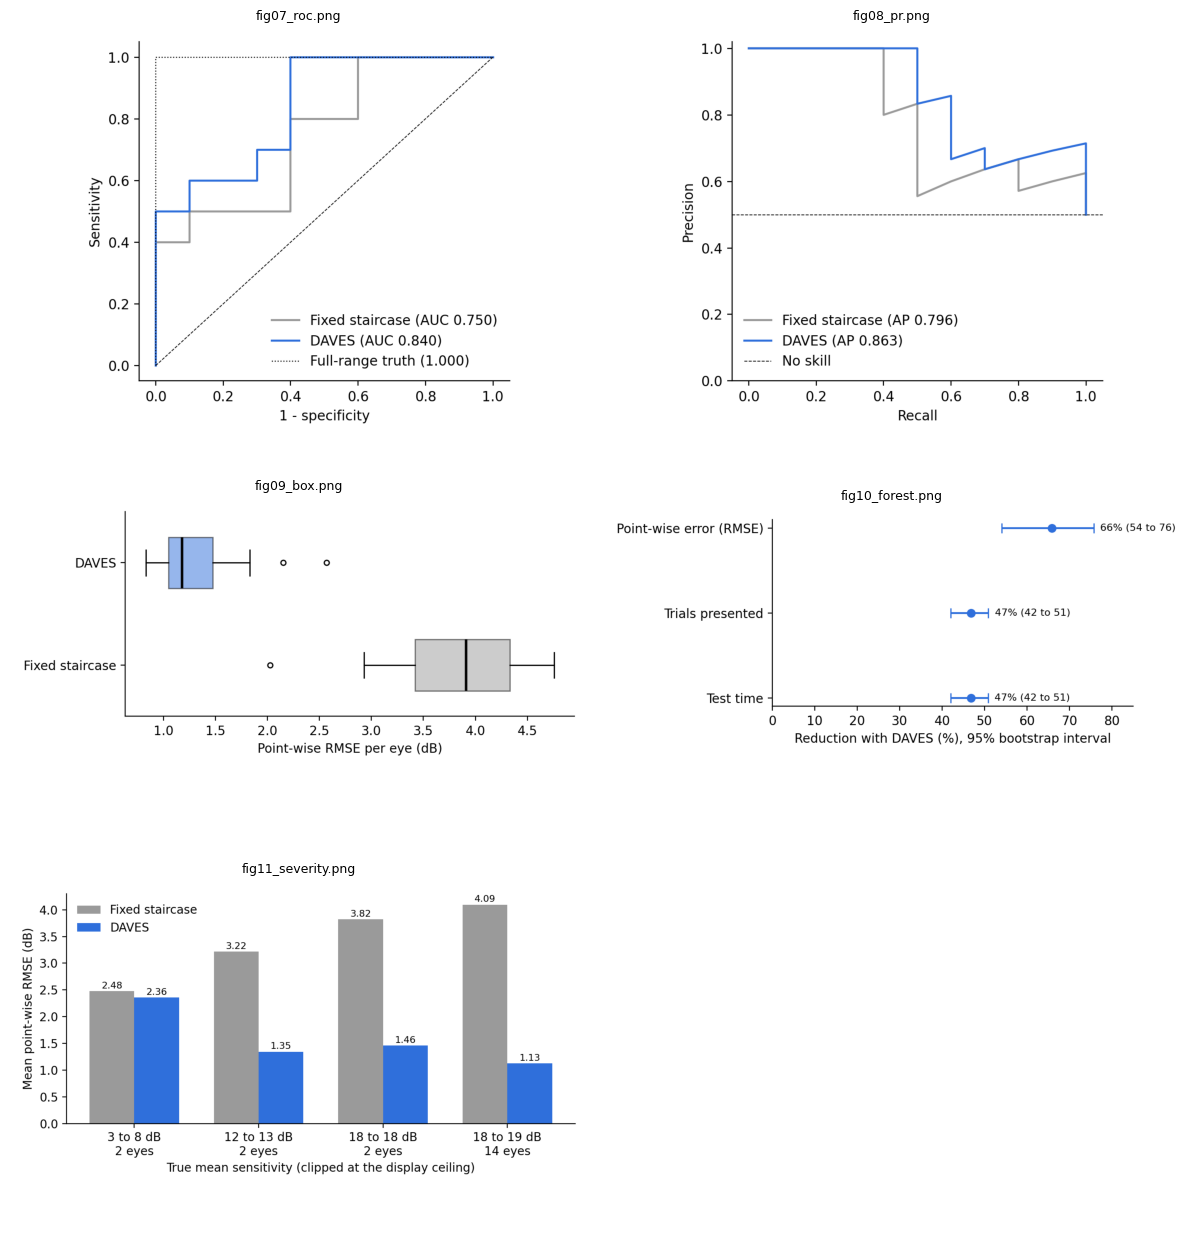

In [7]:
!python -m daves.technical_stats --outdir {OUT} --boot 1000
!python -m daves.plots --outdir {OUT}
show(FIGS, OUT)

In [ ]:
display(pd.read_csv(f"{OUT}/replay_summary.csv").round(3))
display(pd.read_csv(f"{OUT}/technical_stats.csv").round(3))

## 4. Optional: ablation, fixation-loss and display-ceiling experiments (Tables 5 to 7)
Ten configurations. The paper used 60 eyes per class, which is slow on Colab, so the default is small.

In [8]:
EXP_PER_CLASS = 8  #@param {type:"slider", min:4, max:60, step:2}
!python -m daves.replay_experiments --data data/alldata.json --per-class {EXP_PER_CLASS} --seed {SEED} --out {OUT}/experiments.csv
display(pd.read_csv(f"{OUT}/experiments.csv")[["config","gaze_gate","ceiling_db","fixation_loss","bias_db","point_rmse_db","mean_trials","auc"]].round(3))

stair_19         rmse 3.74 dB  trials 728  auc 0.672 (ub 0.922)
gabat_nogate_19  rmse 1.89 dB  trials 381  auc 0.719 (ub 0.922)
gabat_19         rmse 1.27 dB  trials 379  auc 0.797 (ub 0.922)
gabat_15         rmse 1.21 dB  trials 453  auc 0.906 (ub 0.906)
gabat_25         rmse 1.97 dB  trials 571  auc 0.938 (ub 0.953)
gabat_30         rmse 3.10 dB  trials 663  auc 1.000 (ub 1.000)
stair_fl0        rmse 2.18 dB  trials 797  auc 0.703 (ub 0.922)
gabat_fl0        rmse 1.27 dB  trials 346  auc 0.719 (ub 0.922)
stair_fl16       rmse 5.32 dB  trials 649  auc 0.734 (ub 0.922)
gabat_fl16       rmse 1.31 dB  trials 416  auc 0.719 (ub 0.922)
Saved results_full/experiments.csv


,config,gaze_gate,ceiling_db,fixation_loss,bias_db,point_rmse_db,mean_trials,auc
0,stair_19,False,19,0.08,-2.715,3.739,728.250,0.672
1,gabat_nogate_19,False,19,0.08,-1.187,1.889,380.875,0.719
2,gabat_19,True,19,0.08,-0.757,1.268,379.000,0.797
3,gabat_15,True,15,0.08,0.035,1.213,453.188,0.906
4,gabat_25,True,25,0.08,-1.270,1.972,570.562,0.938
5,gabat_30,True,30,0.08,-2.223,3.099,662.812,1.000
6,stair_fl0,False,19,0.00,-1.324,2.185,796.750,0.703
7,gabat_fl0,True,19,0.00,-0.702,1.268,346.500,0.719
8,stair_fl16,False,19,0.16,-4.340,5.323,649.125,0.734
9,gabat_fl16,True,19,0.16,-0.756,1.313,416.188,0.719


## 5. Synthetic check of the oculomotor and physiology modules (Table 8)
Synthetic recordings with known truth: this tests the code, not clinical performance.

In [9]:
!python -m daves.synthetic_validation --repeats 20 --out results/synthetic_validation.csv

                                           check  value  z_flag
saccade detection ratio (detected/true), typical  1.078     2.5
                              flag rate: typical  0.078     2.5
                        flag rate: slow saccades  1.000     2.5
                       flag rate: noisy fixation  1.000     2.5
saccade detection ratio (detected/true), typical  1.078     3.5
                              flag rate: typical  0.018     3.5
                        flag rate: slow saccades  0.983     3.5
                       flag rate: noisy fixation  1.000     3.5
                 heart rate absolute error (bpm)  0.048     NaN
            EDA responses recovered (found/true)  0.901     NaN


### Your own gaze data (optional)
Upload gaze files (for example GazeBaseVR CSVs) and point the module at them. Check the dataset licence and the real column names first.

```
!python -m daves.gaze_health_metrics --gaze-dir my_gaze --x-col x --y-col y --hz 250
```

## 6. Download the results

In [10]:
import shutil
made = []
for d in ("results", OUT):
    if os.path.isdir(d):
        shutil.make_archive(d, "zip", d); made.append(d + ".zip")
try:
    from google.colab import files
    for z in made:
        files.download(z)
except ImportError:
    print("Zips written:", made)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>